# 01 · Reading spectra

**What you'll learn**

- how to read archive spectra as plain arrays with the loaders of `sparta.instruments`
- what one epoch holds: orders, wavelengths, flux, time, barycentric correction
- what `sparta.instruments` records about each spectrograph

SPARTA analyses a *spectroscopic time series*, many spectra of one star taken at different
times: it measures radial velocities and searches the spectra, or the RVs, for periodic signals.
This series builds every step from the public functions on plain arrays (the *atoms*), and
checks it at the end against the objects that chain them. The how-tos in [`../howto/`](../howto/)
are the short recipes; the map of which notebook covers what is in
[examples/README](../README.md).

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import sparta
import unicor
from sparta import instruments
from sparta.plotting import apply_style, plot_data

apply_style()        # SPARTA figure style: data black steps, models red, one extra series blue
print("SPARTA", sparta.__version__)

SPARTA 0.3.0


## Load the bundled data

Two real data sets ship in `examples/data/`:

- `TOI677/`: 12 spectra from **NRES** (the Las Cumbres Observatory echelle network), all 67 echelle orders each;
- `TOI193/`: 32 spectra from **HARPS** (ESO archive 1-D products, one merged spectrum each).

Every archive stores wavelengths, flux, times and the barycentric correction differently.
`sparta.instruments` hides that: `instruments.get(key)` returns the *product* registered under a
survey key, and its `load(path, min_wv=..., max_wv=...)` reads one file into the same plain
container for every archive. HARPS 1-D products cover the whole optical range in one array, so
we choose a wavelength window (`min_wv`, `max_wv`, in Å); multi-order products such as NRES
ignore it.

In [2]:
nres = instruments.get("NRES")
harps = instruments.get("HARPS")

nres_files = sorted(Path("../data/TOI677").glob("*.fits"))
harps_files = sorted(Path("../data/TOI193").glob("*.fits"))
nres_records = [nres.load(p, min_wv=None, max_wv=None) for p in nres_files]     # window ignored
harps_records = [harps.load(p, min_wv=4990, max_wv=5090) for p in harps_files]  # Å

for name, records in [("NRES / TOI-677", nres_records), ("HARPS / TOI-193", harps_records)]:
    times = np.array([r.time for r in records])
    print(f"{name}: {len(records)} epochs, {len(records[0].wave)} order(s), "
          f"spanning {np.ptp(times):.1f} days")
    print(f"    time system: {records[0].time_system!r}, "
          f"wavelength frame: {records[0].wavelength_frame!r}")

NRES / TOI-677: 12 epochs, 67 order(s), spanning 30.9 days
    time system: 'BJD-TDB', wavelength frame: None
HARPS / TOI-193: 32 epochs, 1 order(s), spanning 54.1 days
    time system: 'BJD (HARPS DRS; scale unverified)', wavelength frame: 'air'


`wavelength_frame` is `'air'` for HARPS and `None` for this NRES product: its pipeline does not
document whether its wavelengths are in air or in vacuum (notebook 02 explains why it matters).

## What one epoch holds

Each `load` returns a `LoadedSpectrum`: per-order lists of wavelength (Å) and flux arrays, and
the metadata the analysis needs. No class to learn: the arrays are ordinary NumPy arrays.

In [3]:
rec = nres_records[0]
print(f"{len(rec.wave)} orders; order 0: {rec.wave[0].size} pixels, dtype {rec.wave[0].dtype}")
for i in (0, 33, 66):
    print(f"  order {i:2d}: {rec.wave[i][0]:7.1f} - {rec.wave[i][-1]:7.1f} Å")
print("time:", rec.time, rec.time_system)
print("bcv (km/s):", round(rec.bcv, 4), "  frame of the wavelengths (SPECSYS):", rec.specsys)
print("S/N:", rec.snr, "  native step (km/s):", rec.native_step_kms)

67 orders; order 0: 4096 pixels, dtype float64
  order  0:  8877.5 -  9055.5 Å
  order 33:  5426.2 -  5536.3 Å
  order 66:  3894.5 -  3977.3 Å
time: 2458624.56476 BJD-TDB
bcv (km/s): -13.705   frame of the wavelengths (SPECSYS): TOPOCENT
S/N: nan   native step (km/s): None


NRES numbers its orders from red to blue. The S/N is NaN because this product does not record
it. `native_step_kms` is `None` because the NRES wavelengths *are* the detector pixels; for an
archive that resamples (HARPS, below) it holds the detector step (notebook 02).

**Times.** BJD in days. Differences of a few days are tiny next to 2.46 million, so SPARTA
counts days from the integer day of the first visit, keeping full floating-point precision for
the differences:

In [4]:
t = np.array([r.time for r in nres_records])        # BJD (days)
first_day = int(t.min())
print("first day (BJD):", first_day)
print("days since then:", np.round(t - first_day, 3))
print("files already in time order:", bool(np.all(np.diff(t) > 0)))

first day (BJD): 2458624
days since then: [ 0.565  1.534  2.537  3.52  18.524 19.524 20.513 21.504 27.494 29.456
 30.495 31.476]
files already in time order: True


**Barycentric correction.** The Earth moves around the Sun at up to 30 km/s, which shifts every
spectrum. NRES wavelengths are topocentric (`specsys = 'TOPOCENT'`), and the record carries the
correction `bcv` (km/s) still to be applied: $\lambda_{\rm bary} = \lambda_{\rm topo}\,(1 + v_{\rm bc}/c)$,
which is `unicor.doppler_shift_wave(wave, bcv)`. HARPS archive spectra are already barycentric
(`specsys = 'BARYCENT'`, `bcv = 0`).

In [5]:
nres_bary = [[unicor.doppler_shift_wave(w, r.bcv) for w in r.wave] for r in nres_records]

i = 33
shift = unicor.C_KMS * np.log(nres_bary[0][i] / nres_records[0].wave[i])     # km/s
print("NRES bcv (km/s):", np.round([r.bcv for r in nres_records[:4]], 3), "...")
print(f"epoch 0, order {i}: every pixel moves by {shift.mean():.3f} km/s "
      f"(spread {np.ptp(shift):.1e} km/s)")
print("HARPS:", harps_records[0].specsys, " bcv (km/s):", [r.bcv for r in harps_records[:4]], "...")

NRES bcv (km/s): [-13.705 -13.785 -13.903 -13.99 ] ...
epoch 0, order 33: every pixel moves by -13.705 km/s (spread 6.7e-11 km/s)
HARPS: BARYCENT  bcv (km/s): [0.0, 0.0, 0.0, 0.0] ...


## Look at a spectrum

These are the spectra as the archives deliver them, not normalised. In the NRES order, note
the unexposed margins at both ends (the pipeline pads each order with background-subtracted
detector, which reads zero plus noise), the noisier order edges and the narrow upward spikes
(cosmic-ray hits). Notebook 03 shows the preprocessing that deals with all three. The
three strong NRES lines are the Mg b triplet (5167, 5173 and 5184 Å).

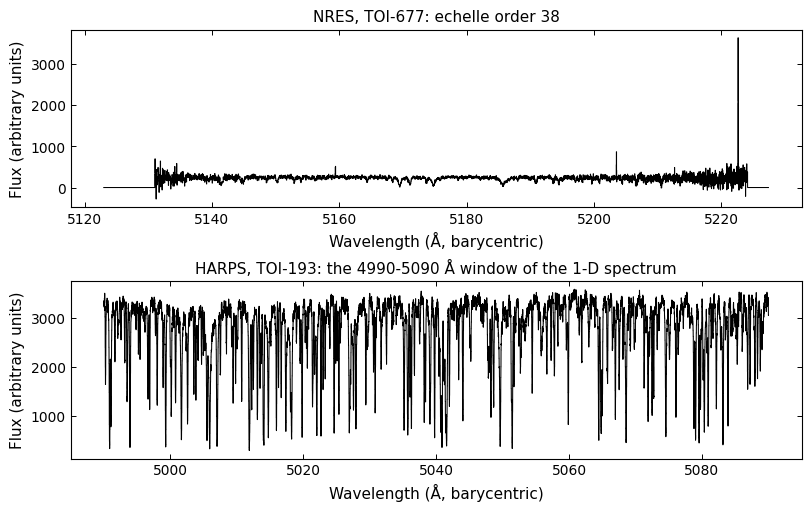

In [6]:
wave0, flux0 = nres_bary[0], nres_records[0].flux
order = next(i for i, w in enumerate(wave0) if w[0] < 5175 < w[-1])
hrec = harps_records[0]

fig, axs = plt.subplots(2, 1, figsize=(8, 5))
plot_data(axs[0], wave0[order], flux0[order])
axs[0].set_title(f"NRES, TOI-677: echelle order {order}")
plot_data(axs[1], hrec.wave[0], hrec.flux[0])
axs[1].set_title("HARPS, TOI-193: the 4990-5090 Å window of the 1-D spectrum")
for ax in axs:
    ax.set_xlabel("Wavelength (Å, barycentric)")
    ax.set_ylabel("Flux (arbitrary units)")
plt.show()

## What `sparta.instruments` knows

Each survey key maps to a `Product` (one archive data product) and its `Instrument`. They record
what the analysis needs to know: resolving power, native pixel size, wavelength frame, time
system, and starting-point analysis settings.

In [7]:
print("survey keys:", ", ".join(sorted(instruments.REGISTRY)))

survey keys: APOGEE, CORALIE, ELODIE, FEROS, FEROS-CERES, HARPS, HARPS-CERES, LAMOST, NRES, NRES-BANZAI, PEPSI, SIMULATED, SRG, TRES, UVES


In [8]:
for product in (nres, harps):
    inst, rec = product.instrument, product.recommended
    fwhm = unicor.C_KMS / inst.resolving_power              # km/s
    print(f"{product.survey}: {product.description}")
    print(f"    R = {inst.resolving_power:,.0f}  ->  line-spread FWHM c/R = {fwhm:.2f} km/s")
    print(f"    native (detector) step = {inst.native_step_kms:.3f} km/s per pixel "
          f"({fwhm / inst.native_step_kms:.1f} pixels per FWHM)")
    print(f"    archive grid: {product.grid}; resampled by the archive: {product.resampled}")
    print(f"    wavelength frame: {product.wavelength_frame}, SPECSYS: {product.specsys}, "
          f"time: {product.time_system}")
    print(f"    recommended: dv = {rec.dv_kms} km/s, window = {rec.window_A}, "
          f"drop {len(rec.drop_orders)} orders")
    print(f"    recommended preprocess: {rec.preprocess}\n")

assert harps_records[0].native_step_kms == [harps.instrument.native_step_kms]

NRES: NRES commissioning (IDL) pipeline extracted spectrum, RLEVEL 91 ('*-e91.fits'): HDU2 SPECFLAT flux and HDU6 WAVESPEC wavelengths (nm), 67 orders x 4096 pixels.
    R = 53,000  ->  line-spread FWHM c/R = 5.66 km/s
    native (detector) step = 1.450 km/s per pixel (3.9 pixels per FWHM)
    archive grid: native echelle pixels; resampled by the archive: False
    wavelength frame: None, SPECSYS: TOPOCENT, time: BJD-TDB
    recommended: dv = 0.05 km/s, window = None, drop 27 orders
    recommended preprocess: {'n_trim': 100, 'clean_margins': True, 'remove_nans': True, 'delta': 0.5, 'cosmic_sigma': 3, 'filter_lowcut': 4, 'filter_highcut': 0.15, 'alpha': 0.3}

HARPS: ESO Phase-3 SDP 1-D spectrum (ADP.*.fits, HARPS DRS s1d): one-row binary table in HDU1 with WAVE / FLUX / ERR columns.
    R = 120,000  ->  line-spread FWHM c/R = 2.50 km/s
    native (detector) step = 0.609 km/s per pixel (4.1 pixels per FWHM)
    archive grid: linear, 0.01 Angstrom per pixel (SPEC_BIN = 0.001 nm); resampl

A few things to notice:

- **Resolving power** sets the narrowest line width, $c/R$: 5.7 km/s for NRES, 2.5 km/s for HARPS.
- The **native step** is the detector pixel in velocity. The HARPS archive spectrum is
  *resampled* onto a 0.01 Å grid, finer than the detector in the red, so its loader attaches the
  detector step to every record (`native_step_kms`, checked above): the extra samples are not
  extra information (notebook 02).
- The **recommended settings** are starting points that worked on these data sets, not
  instrument documentation.
- The `SIMULATED` key builds synthetic spectra "as if" from a real product, with a known truth.
  Notebooks 03–06 and 09 use it.

[docs/instruments.md](../../docs/instruments.md) lists every product.

**Units.** Plain numbers are wavelengths in Å, velocities in km/s, times in days and frequencies
in 1/day ([conventions § units](../../docs/conventions.md#units)).

## The same arrays with the objects

`Observations` is this notebook in one call: it loads every file of a directory with the
product's loader (in sorted order), applies `doppler_shift_wave(wave, bcv)` to each order, and
counts the times from the first integer day. The arrays are identical, bit for bit
([`howto/01_measure_rvs`](../howto/01_measure_rvs.ipynb) starts this way):

In [9]:
from sparta import Observations

obs_nres = Observations(survey="NRES", target_visits_lib="../data/TOI677/")
obs_harps = Observations(survey="HARPS", target_visits_lib="../data/TOI193/", min_wv=4990, max_wv=5090)

for obs, records in [(obs_nres, nres_records), (obs_harps, harps_records)]:
    first = int(min(r.time for r in records))
    assert obs.first_time == first
    assert np.array_equal(obs.time_list, [r.time - first for r in records])
    assert np.array_equal(obs.bcv, [r.bcv for r in records])
    for spec, r in zip(obs.spec_list, records):
        assert all(np.array_equal(w, unicor.doppler_shift_wave(w0, r.bcv))
                   for w, w0 in zip(spec.wv, r.wave))
        assert all(np.array_equal(s, s0) for s, s0 in zip(spec.sp, r.flux))
    print(f"{obs.spec_list[0].name}: {obs.sample_size} epochs, the same wavelengths, flux, "
          f"times and bcv as the loader")

NRES: 12 epochs, the same wavelengths, flux, times and bcv as the loader
HARPS: 32 epochs, the same wavelengths, flux, times and bcv as the loader


## Summary / next

- `instruments.get(key).load(path, min_wv=..., max_wv=...)` reads one archive file into plain
  arrays: per-order wavelengths (Å) and flux, the time (days), `bcv` (km/s) and the frames.
- `unicor.doppler_shift_wave(wave, bcv)` applies the barycentric correction.
- `instruments.get(key)` also gives the resolving power, native step, frames and recommended
  settings.
- `Observations(survey=..., target_visits_lib=...)` does all of the above for a directory.

**Next:** [`02_log_lambda`](02_log_lambda.ipynb): why cross-correlation needs a log-λ grid.